# Insper - Modelagem e Simulação do Mundo Físico

## Projeto 2 - Termodinâmica | Grupo 10

---
## 1. Definição do modelo

**Sistema:** panela de aço inox com 1 L de água, sem tampa, esquentando em um fogão de **indução**. O fogão esquenta o fundo da panela, e a panela esquenta a água.

**Pergunta:** quanto tempo a água demora para ferver em função da potência do fogão?

**Hipóteses:**
- A panela é um cilindro de aço de raio $r$, altura $H$ e espessura $d$ pequena.
- Panela e água têm temperatura uniforme ($T_p$ e $T_a$) e capacidade térmica não desprezível, ou seja, são **2 estoques**.
- Ambiente a $T_{amb} = 18,9\ °C$ (medida no experimento). Consideramos que a água ferve a $100\ °C$.
- Não há convecção na água, mas há no ar (como na latinha da Aula 15).
- O fundo da panela está apoiado no fogão e não perde calor para o ambiente.
- Desprezamos a radiação e a evaporação.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

---
## 2. Modelagem

### 2.1 - Esquema físico

<div style="text-align: center;">
    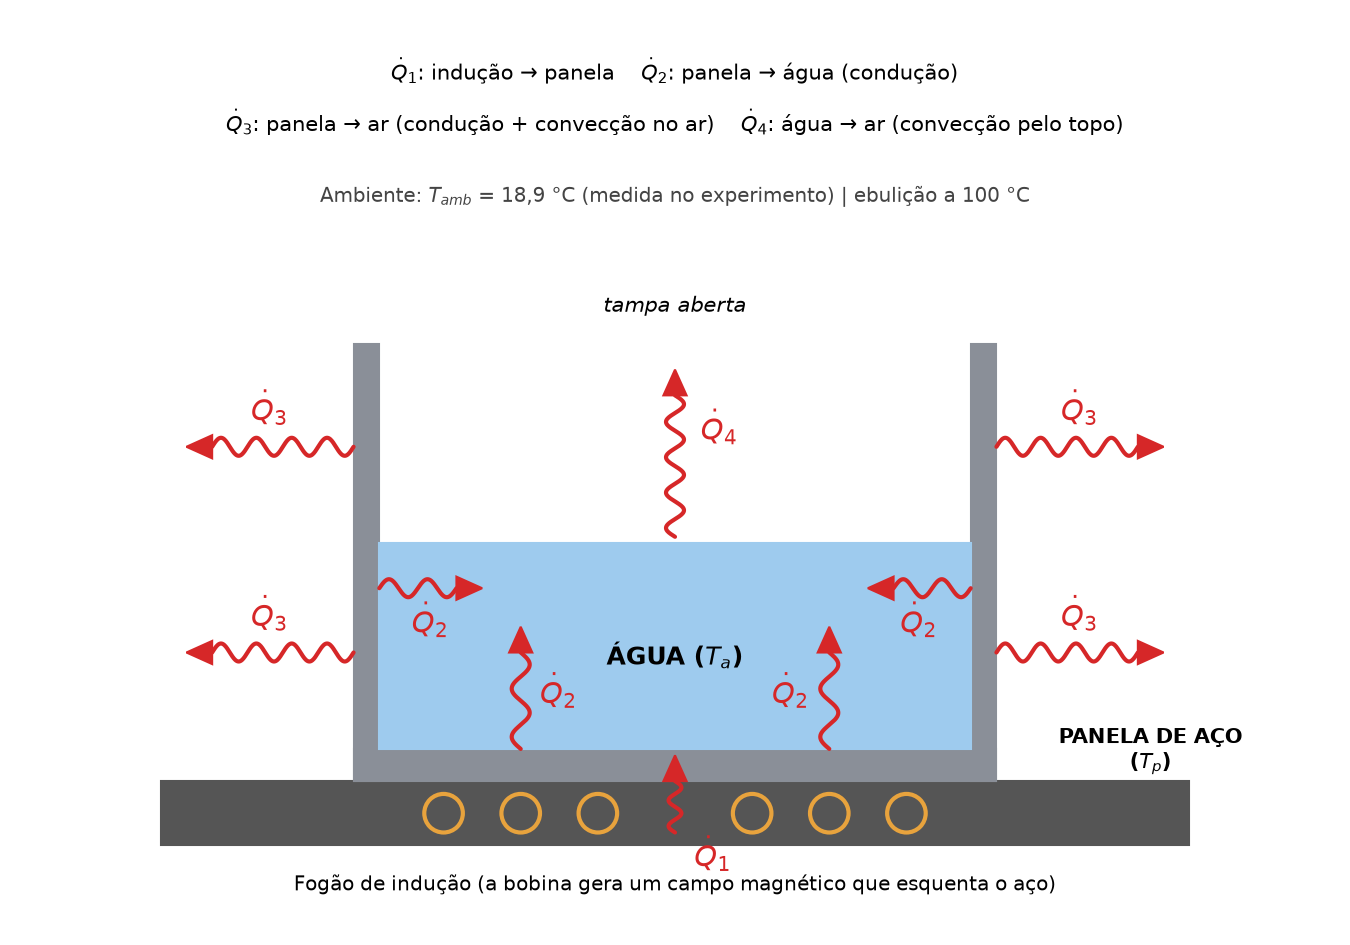
</div>

- $\dot{Q}_1$: calor gerado pelo fogão de indução no fundo da panela.
- $\dot{Q}_2$: calor da panela para a água (condução).
- $\dot{Q}_3$: calor da panela para o ar pelas paredes, em toda a altura (condução + convecção no ar).
- $\dot{Q}_4$: calor da água para o ar pelo topo aberto (convecção).

### 2.2 - Diagrama de estoques e fluxos

<div style="text-align: center;">
    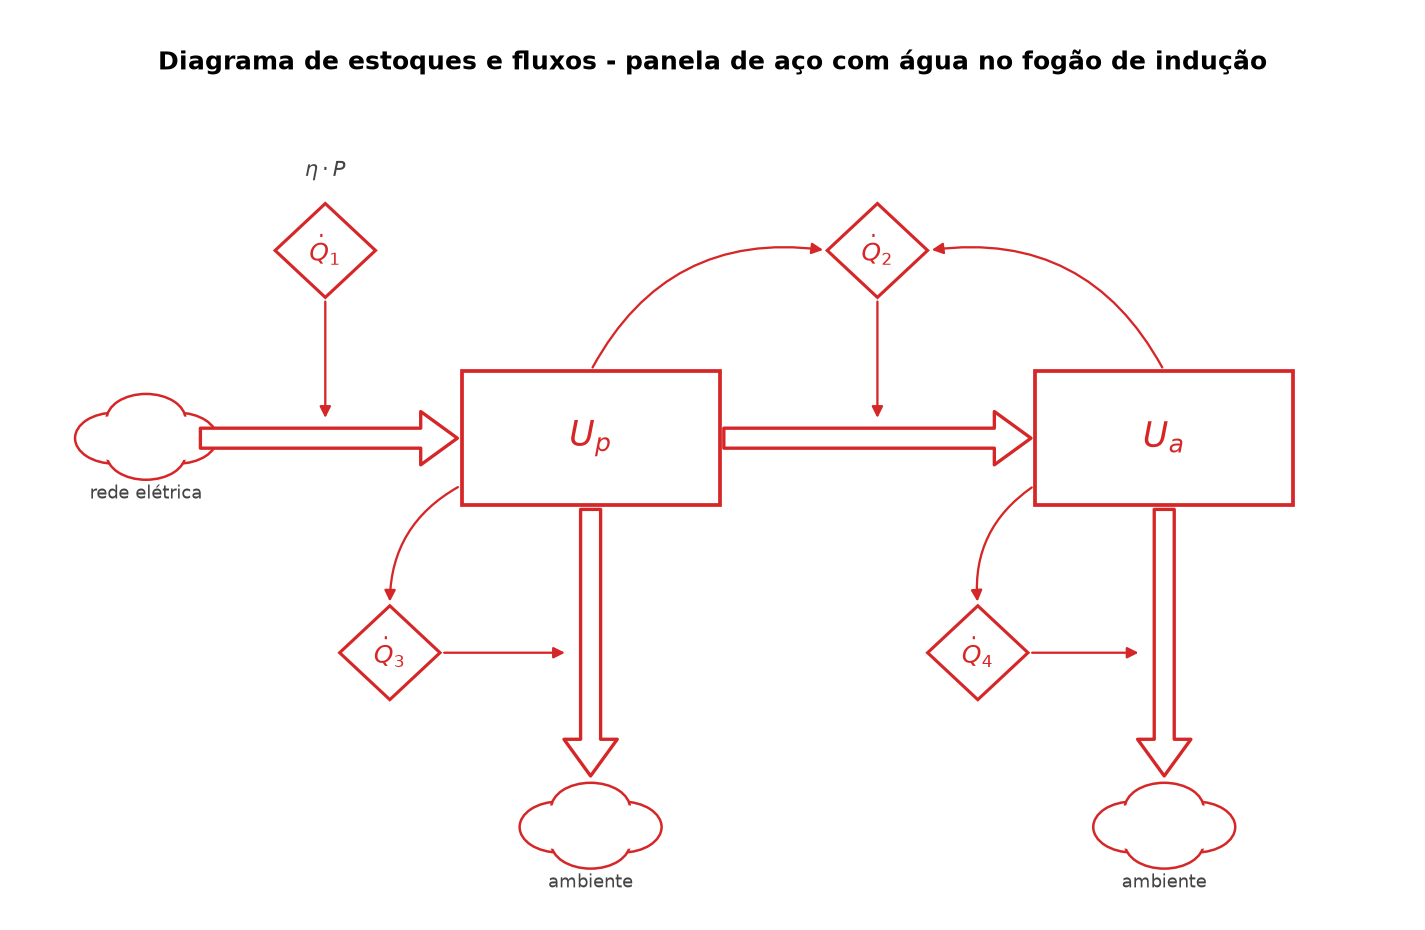
</div>

- $U_p$: energia interna da panela
- $U_a$: energia interna da água

### 2.3 - Equações diferenciais

**Balanço de energia** (o que entra menos o que sai de cada estoque):

$$
\left\{
    \begin{array}{l}
        \dfrac{dU_p}{dt} = \dot{Q}_1 - \dot{Q}_2 - \dot{Q}_3 \\
        \dfrac{dU_a}{dt} = \dot{Q}_2 - \dot{Q}_4 \\
    \end{array}
\right.
$$

**Fluxos de calor.** $\dot{Q}_1 = \eta \cdot P$ é a potência útil do fogão. Como na latinha da Aula 15, $\dot{Q}_2$, $\dot{Q}_3$ e $\dot{Q}_4$ são escritos com **resistências térmicas**, $\dot{Q} = \dfrac{\Delta T}{R}$:

<div style="text-align: center;">
    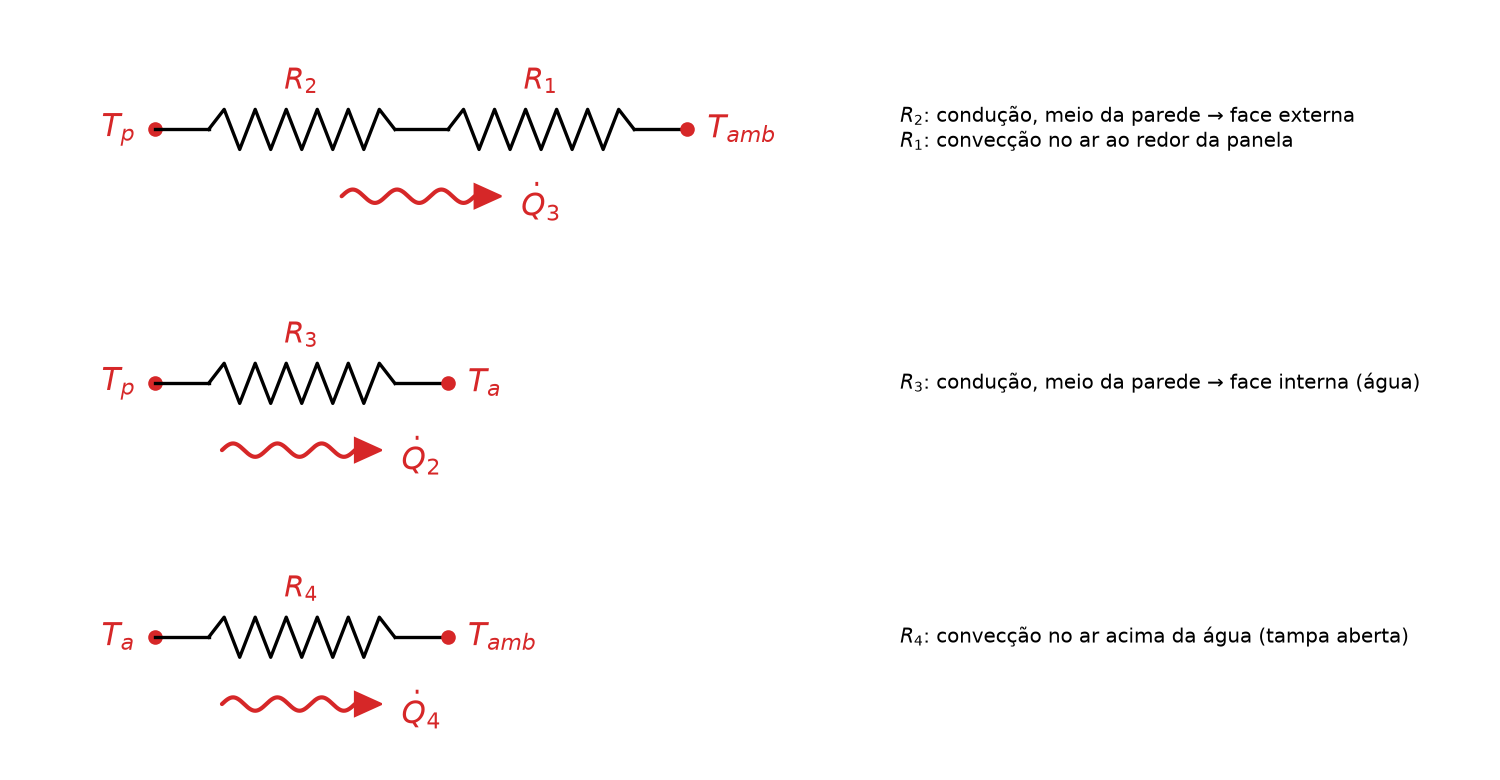
</div>

- $R_1$: resistência de **convecção** no ar ao redor da panela.
- $R_2$: resistência de **condução** do "meio" da parede até a face externa, ao longo de uma espessura $\frac{d}{2}$.
- $R_3$: resistência de **condução** do "meio" da parede até a face interna, que está em contato com a água, ao longo de uma espessura $\frac{d}{2}$.
- $R_4$: resistência de **convecção** no ar acima da superfície da água (tampa aberta).

$$R_1 = \frac{1}{h_{ar} \cdot A_{lat}} \qquad R_2 = \frac{d/2}{k_{aço} \cdot A_{lat}} \qquad R_3 = \frac{d/2}{k_{aço} \cdot A_{pa}} \qquad R_4 = \frac{1}{h_{ar} \cdot A_{sup}}$$

$$\dot{Q}_2 = \frac{T_p - T_a}{R_3} \qquad \dot{Q}_3 = \frac{T_p - T_{amb}}{R_1 + R_2} \qquad \dot{Q}_4 = \frac{T_a - T_{amb}}{R_4}$$

Nessas fórmulas:
- $T_p$: temperatura da panela [°C].
- $T_a$: temperatura da água [°C].
- $T_{amb}$: temperatura do ar ambiente [°C], que é constante.

$T_p$ e $T_a$ **não têm um valor fixo**: elas mudam com o tempo e são justamente o que o modelo calcula (com o `odeint`). O que definimos é só o valor delas no início, em $t = 0$ (ver seção 2.4).

**Equações para o `odeint`.** Como $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$:

$$
\left\{
    \begin{array}{l}
        \dfrac{dT_p}{dt} = \dfrac{1}{m_p \cdot c_p} \cdot \left( \eta \cdot P - \dfrac{T_p - T_a}{R_3} - \dfrac{T_p - T_{amb}}{R_1 + R_2} \right) \\[4mm]
        \dfrac{dT_a}{dt} = \dfrac{1}{m_a \cdot c_a} \cdot \left( \dfrac{T_p - T_a}{R_3} - \dfrac{T_a - T_{amb}}{R_4} \right) \\
    \end{array}
\right.
$$

**De onde vem cada fórmula** (apostila, Aulas 14 a 16):

| Fórmula | Origem |
|---|---|
| $\dfrac{dU}{dt} = \sum \dot{Q}_{entra} - \sum \dot{Q}_{sai}$ | 1ª Lei da Termodinâmica (sem trabalho) |
| $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$ | calor sensível, $Q = m \cdot c \cdot \Delta T$ |
| $\dot{Q}_1 = \eta \cdot P$ | rendimento: potência útil = rendimento × potência elétrica |
| $R_{cond} = \dfrac{L}{k \cdot A}$ | lei de Fourier (condução) |
| $R_{conv} = \dfrac{1}{h \cdot A}$ | lei de Newton do resfriamento (convecção) |

### 2.4 - Parâmetros

| Parâmetro | Símbolo | Valor | Unidade | Origem |
|---|---|---|---|---|
| raio da panela | $r$ | 0,080 | m | **medido**: diâmetro de 160,0 mm (média de 10 medidas) |
| altura da panela | $H$ | 0,0812 | m | **medido**: altura de 81,2 mm (média de 5 medidas) |
| espessura da parede | $d$ | 0,00054 | m | **medido**: espessura de 0,54 mm (média de 5 medidas) |
| massa da panela | $m_p$ | 1,123 | kg | **medido**: 1123 g na balança |
| calor específico do aço | $c_p$ | 500 | J/(kg·K) | tabela |
| condutividade do aço | $k_{aço}$ | 16 | W/(m·K) | tabela |
| massa de água | $m_a$ | 1,0 | kg | 1 L |
| calor específico da água | $c_a$ | 4186 | J/(kg·K) | tabela |
| potência elétrica média do fogão | $P$ | 200 | W | média no experimento: o fogão liga e desliga (ver abaixo); varia no gráfico conclusivo |
| eficiência da indução | $\eta$ | 0,85 | - | típico: 0,84 a 0,90 |
| convecção no ar | $h_{ar}$ | 60 | W/(m²·K) | **ajustado** para o modelo estabilizar na temperatura medida, cerca de $66\ °C$ (ver abaixo) |
| temperatura ambiente | $T_{amb}$ | 18,9 | °C | **medido** no experimento |
| temperatura de ebulição | $T_{eb}$ | 100 | °C | nível do mar |

**Condições iniciais** (medidas no início do experimento; consideramos a água na mesma temperatura da panela):

| Variável | Símbolo | Valor inicial | Unidade |
|---|---|---|---|
| temperatura da panela | $T_p(0)$ | 20,7 | °C |
| temperatura da água | $T_a(0)$ | 20,7 | °C |

**Áreas:**
- $A_{sup} = \pi r^2$: topo da água.
- $A_{pa} = \pi r^2 + 2 \pi r \cdot h_{agua}$: panela em contato com a água, sendo $h_{agua}$ a altura da água.
- $A_{lat} = 2 \pi r H$: lateral da panela.

**Por que $P = 200\ W$:** no experimento, o fogão ficou no modo $150\ °C$. Nesse modo ele **liga e desliga** ao longo do tempo para controlar a temperatura. Medimos a tensão da tomada ($220\ V$, valor eficaz) e a corrente máxima com o fogão ligado ($3,2\ A$). Com o fogão ligado, a potência é $P_{ligado} = V_{ef} \cdot \dfrac{I_{máx}}{\sqrt{2}} \approx 498\ W$ (calculada no código). Como ele não fica ligado o tempo todo, a potência que importa para o modelo é a **média**. A média que reproduz os dados é $P \approx 200\ W$, ou seja, o fogão ficou ligado cerca de $40\%$ do tempo.

**Por que $h_{ar} = 60$:** com $P = 200\ W$ a água **não ferveu**: ela estabilizou perto de $66\ °C$, porque o calor que entra passou a ser igual ao calor perdido para o ambiente (equilíbrio térmico). Com $h_{ar} = 10$ (convecção natural), o modelo perdia pouco calor e a água fervia. Testamos valores maiores e $h_{ar} = 60$ fez o modelo estabilizar na mesma temperatura do experimento. O valor fica acima da faixa da convecção natural (2 a 25) porque, no modelo, ele também representa as perdas que desprezamos: **evaporação** (a panela está sem tampa) e **radiação**.

Usamos a potência **elétrica** $P$, e não a útil, porque é o valor que se escolhe no fogão e que se conhece no experimento.

Fontes dos valores de tabela: engineeringtoolbox.com e Incropera, *Fundamentos de Transferência de Calor e de Massa*.

In [3]:
# ---------------- Panela ----------------
r = 0.080         # raio [m] (medido: diâmetro 160,0 mm)
H = 0.0812        # altura [m] (medido: 81,2 mm)
d = 0.00054       # espessura da parede [m] (medido: 0,54 mm)
m_p = 1.123       # massa [kg] (medida: 1123 g)
c_p = 500         # calor específico do aço [J/(kg.K)]
k_aco = 16        # condutividade térmica do aço [W/(m.K)]

# ---------------- Água ----------------
m_a = 1.0         # massa [kg] (1 L)
c_a = 4186        # calor específico [J/(kg.K)]

# ---------------- Fogão e ambiente ----------------
V_ef = 220                        # tensão eficaz da tomada [V]
I_max = 3.2                       # corrente máxima medida com o fogão ligado [A]
P_ligado = V_ef * I_max / np.sqrt(2)   # potência com o fogão ligado [W] (~498 W)
P = 200           # potência elétrica MÉDIA [W] (o fogão liga e desliga no modo 150 °C)
eta = 0.85        # eficiência da indução [-]
h_ar = 60         # coef. de convecção do ar [W/(m2.K)] (ajustado, ver 2.4)
T_amb = 18.9      # temperatura ambiente [°C] (medida)
T_eb = 100        # temperatura de ebulição [°C]

# ---------------- Condições iniciais ----------------
T_p0 = 20.7       # temperatura inicial da panela [°C] (medida)
T_a0 = 20.7       # temperatura inicial da água [°C] (igual à da panela)

# ---------------- Áreas [m2] ----------------
A_sup = np.pi * r**2                      # topo da água
h_agua = (m_a / 1000) / A_sup             # altura da água [m]
A_pa = A_sup + 2 * np.pi * r * h_agua     # panela em contato com a água
A_lat = 2 * np.pi * r * H                 # lateral da panela

# ---------------- Resistências térmicas [K/W] ----------------
R1 = 1 / (h_ar * A_lat)                   # convecção: ar ao redor da panela
R2 = (d / 2) / (k_aco * A_lat)            # condução: meio da parede -> face externa
R3 = (d / 2) / (k_aco * A_pa)             # condução: meio da parede -> face interna (água)
R4 = 1 / (h_ar * A_sup)                   # convecção: ar acima da superfície da água

---
## 3. Implementação

### 3.1 - Função do modelo

A função `modelo` é a que o `odeint` usa para resolver as equações da seção 2.3.

Ela recebe, nessa ordem:
- Uma **lista** com $T_p(t)$ e $T_a(t)$
- O instante de tempo $t$

E devolve:
- Uma **lista** com as taxas de variação $\dfrac{dT_p}{dt}$ e $\dfrac{dT_a}{dt}$

Dentro dela calculamos os fluxos de calor $\dot{Q}_1$, $\dot{Q}_2$, $\dot{Q}_3$ e $\dot{Q}_4$ com as resistências $R_1$ a $R_4$ da seção 2.4.

In [4]:
def modelo(x, t):
    T_p = x[0]    # temperatura da panela [°C]
    T_a = x[1]    # temperatura da água [°C]

    # Fluxos de calor [W]
    Q1 = eta * P                       # fogão -> panela
    Q2 = (T_p - T_a) / R3              # panela -> água
    Q3 = (T_p - T_amb) / (R1 + R2)     # panela -> ar
    Q4 = (T_a - T_amb) / R4            # água -> ar

    # Taxas de variação das temperaturas [°C/s]
    dTpdt = (Q1 - Q2 - Q3) / (m_p * c_p)
    dTadt = (Q2 - Q4) / (m_a * c_a)

    dxdt = [dTpdt, dTadt]
    return dxdt

### 3.2 - Gráfico das temperaturas

Usando a função `modelo`, resolvemos as equações com o `odeint` para a potência do experimento ($P = 200\ W$), com uma lista de tempo de $0$ a $7200\ s$ (2 horas) e passo de $1\ s$, partindo das condições iniciais $T_p(0) = T_a(0) = 20,7\ °C$.

Com um `while`, procuramos o instante em que a água chega a $100\ °C$. Como desprezamos a evaporação, o modelo só vale até a água ferver, então, se ela ferver, o gráfico vai só até esse instante. Se ela não ferver (como com $200\ W$), o gráfico mostra as 2 horas e a água se aproxima de uma temperatura constante: o **equilíbrio térmico**, em que o calor que entra é igual ao que sai.

Com P = 200 W, a água não ferve: depois de 120 min ela está a 74.3 °C (equilíbrio térmico)


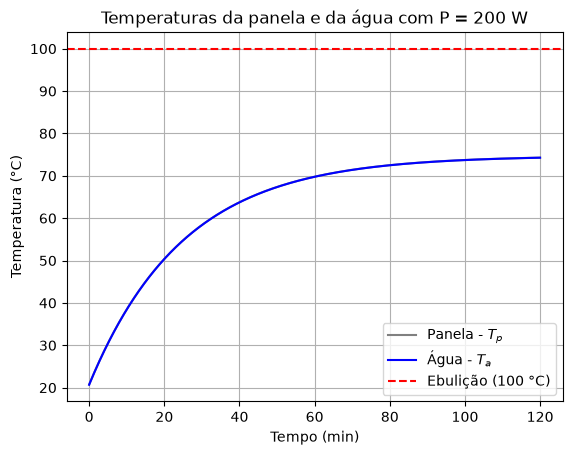

In [5]:
# Define condições iniciais T_p(0) e T_a(0) e lista de tempo
x0 = [T_p0, T_a0]
dt = 1                               # passo de tempo [s]
t_lista = np.arange(0, 7200, dt)     # tempo [s] (2 horas)

x = odeint(modelo, x0, t_lista)
T_p_lista = x[:, 0]
T_a_lista = x[:, 1]

# Procura o instante em que a água ferve
i = 0
while i < len(t_lista) - 1 and T_a_lista[i] < T_eb:
    i = i + 1

if T_a_lista[i] >= T_eb:
    print(f"Com P = {P} W, a água ferve em {t_lista[i]} s = {t_lista[i]/60:.1f} min")
else:
    print(f"Com P = {P} W, a água não ferve: depois de {t_lista[-1]/60:.0f} min ela está a {T_a_lista[-1]:.1f} °C (equilíbrio térmico)")

# Plota até a água ferver ou até o fim da lista de tempo (tempo em minutos)
plt.plot(t_lista[:i+1] / 60, T_p_lista[:i+1], 'gray', label='Panela - $T_p$')
plt.plot(t_lista[:i+1] / 60, T_a_lista[:i+1], 'b', label='Água - $T_a$')
plt.axhline(T_eb, color='r', linestyle='--', label='Ebulição (100 °C)')

# Configura gráfico
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura (°C)')
plt.title(f'Temperaturas da panela e da água com P = {P} W')
plt.legend()
plt.grid(True)
plt.show()

### 3.3 - Comportamento em 60 minutos

Mesmo resultado do item 3.2 (mesma potência $P$), mas com o eixo do tempo indo até $60\ min$. Se a água ferver, as curvas terminam quando ela chega a $100\ °C$, porque depois disso o modelo não vale mais (desprezamos a evaporação).

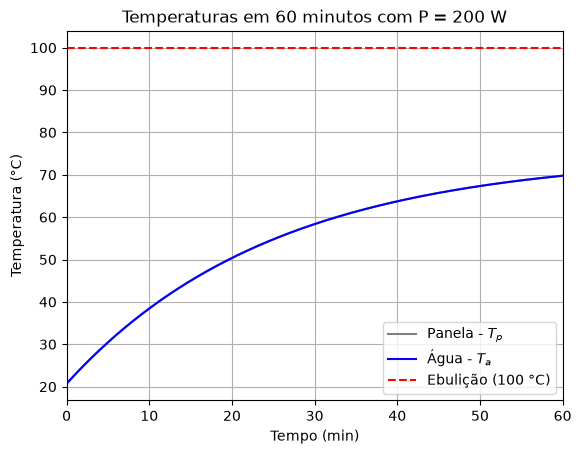

In [6]:
# Usa as listas do item 3.2: as curvas vão só até a água ferver (índice i)
plt.plot(t_lista[:i+1] / 60, T_p_lista[:i+1], 'gray', label='Panela - $T_p$')
plt.plot(t_lista[:i+1] / 60, T_a_lista[:i+1], 'b', label='Água - $T_a$')
plt.axhline(T_eb, color='r', linestyle='--', label='Ebulição (100 °C)')

# Configura gráfico: eixo do tempo de 0 a 60 min
plt.xlim(0, 60)
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura (°C)')
plt.title(f'Temperaturas em 60 minutos com P = {P} W')
plt.legend()
plt.grid(True)
plt.show()

---
## 4. Validação

**Experimento:**
1. Medimos a panela (diâmetro, altura e espessura) e colocamos os valores na seção 2.4.
2. Colocamos $1\ L$ de água, sem tampa, e anotamos as temperaturas iniciais: ambiente $18,9\ °C$ e panela $20,7\ °C$.
3. Ligamos o fogão no modo $150\ °C$. Nesse modo ele liga e desliga; a potência média ficou em cerca de $200\ W$ (ver seção 2.4).
4. Anotamos a temperatura da água **a cada 3 minutos, de 3 a 96 minutos**.

Com $200\ W$ a água não ferveu: ela estabilizou perto de $66\ °C$ (equilíbrio térmico).

Na validação, o **tempo total** da simulação é o tempo que o experimento levou: a lista de tempo vai de $0$ até o último instante medido.

A célula abaixo plota o modelo e os dados medidos **no mesmo gráfico** e calcula o **erro percentual médio** entre eles. Depois que a água ferve, o modelo fica parado em $T_{eb}$, porque a água não passa da temperatura de ebulição.

Tempo total do experimento: 5760 s = 96.0 min
Erro percentual médio: 19.7 %


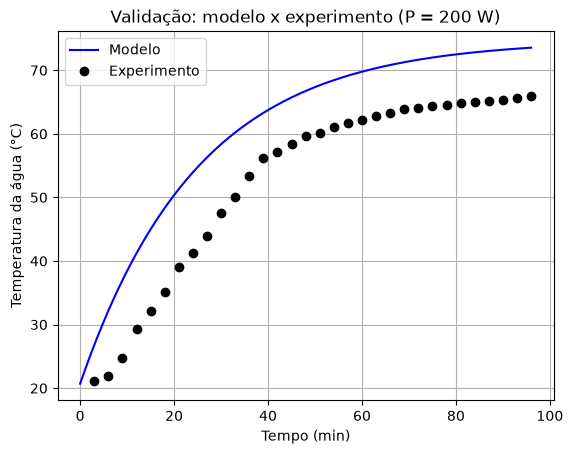

In [7]:
# ---------------- DADOS DO EXPERIMENTO ----------------
# Temperatura da água medida a cada 3 min, de 3 a 96 min (P = 200 W)
t_exp_min = np.arange(3, 96 + 3, 3)      # instantes medidos [min]
t_exp_lista = t_exp_min * 60             # instantes medidos [s]
T_exp_lista = [21.1, 21.9, 24.8, 29.3, 32.1, 35.2, 39.0, 41.2,
               44.0, 47.5, 50.1, 53.3, 56.2, 57.2, 58.4, 59.7,
               60.2, 61.0, 61.7, 62.1, 62.8, 63.3, 63.9, 64.1,
               64.4, 64.6, 64.9, 65.0, 65.2, 65.3, 65.7, 65.9]   # temperaturas da água [°C]
# -------------------------------------------------------

# Tempo total = tempo que o experimento levou (último instante medido)
if len(t_exp_lista) > 0:
    t_total = max(t_exp_lista)       # [s]
else:
    t_total = 600                    # sem dados ainda: simula 10 min [s]

# Define condições iniciais e lista de tempo da validação
x0 = [T_p0, T_a0]
t_lista_val = np.arange(0, t_total + dt, dt)

x = odeint(modelo, x0, t_lista_val)
T_a_lista = np.minimum(x[:, 1], T_eb)    # depois de ferver, a água fica em T_eb

plt.plot(t_lista_val / 60, T_a_lista, 'b', label='Modelo')

if len(t_exp_lista) > 0:
    t_exp = np.array(t_exp_lista)
    T_exp = np.array(T_exp_lista)
    plt.plot(t_exp / 60, T_exp, 'ko', label='Experimento')

    # Temperatura do modelo nos mesmos instantes em que medimos
    T_modelo = np.interp(t_exp, t_lista_val, T_a_lista)
    erro_medio = np.mean(np.abs(T_modelo - T_exp) / T_exp) * 100
    print(f"Tempo total do experimento: {t_total} s = {t_total/60:.1f} min")
    print(f"Erro percentual médio: {erro_medio:.1f} %")
else:
    print("Sem dados do experimento ainda: preencha t_exp_lista e T_exp_lista.")

# Configura gráfico
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura da água (°C)')
plt.title(f'Validação: modelo x experimento (P = {P} W)')
plt.legend()
plt.grid(True)
plt.show()

---
## 5. Gráfico conclusivo

Para responder à pergunta (*quanto tempo a água demora para ferver em função da potência do fogão?*), criamos a função `modelo2`. Ela é igual à `modelo`, mas recebe a potência $P$ como argumento a mais.

Depois rodamos o `odeint` em um **loop**, uma vez para cada potência de $100\ W$ a $3500\ W$ (de $50$ em $50\ W$), mantendo todos os outros parâmetros iguais. Em cada simulação, guardamos o tempo que a água leva para chegar a $T_{eb}$. Se a água não ferver dentro da lista de tempo (2 horas), guardamos `np.nan` e esse ponto não aparece no gráfico.

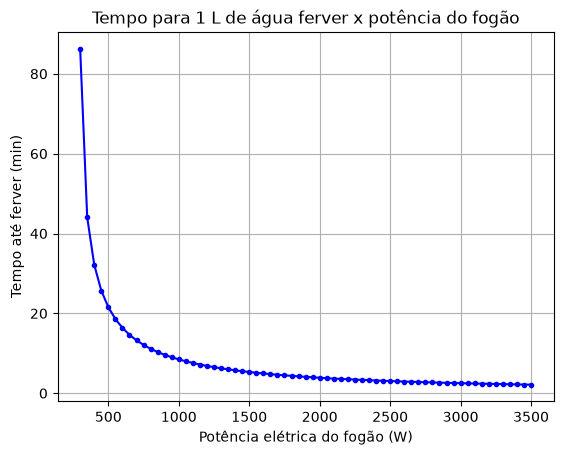

In [8]:
# Igual à função modelo, mas recebe a potência P [W] como argumento
def modelo2(x, t, P):
    T_p = x[0]    # temperatura da panela [°C]
    T_a = x[1]    # temperatura da água [°C]

    # Fluxos de calor [W]
    Q1 = eta * P                       # fogão -> panela
    Q2 = (T_p - T_a) / R3              # panela -> água
    Q3 = (T_p - T_amb) / (R1 + R2)     # panela -> ar
    Q4 = (T_a - T_amb) / R4            # água -> ar

    # Taxas de variação das temperaturas [°C/s]
    dTpdt = (Q1 - Q2 - Q3) / (m_p * c_p)
    dTadt = (Q2 - Q4) / (m_a * c_a)

    dxdt = [dTpdt, dTadt]
    return dxdt


P_lista = np.arange(100, 3500 + 50, 50)    # potências testadas [W]
t_eb_lista = []                            # tempo até ferver [s]

x0 = [T_p0, T_a0]
for P_atual in P_lista:
    x = odeint(modelo2, x0, t_lista, args=(P_atual,))
    T_a_lista = x[:, 1]

    i = 0
    while i < len(t_lista) - 1 and T_a_lista[i] < T_eb:
        i = i + 1

    if T_a_lista[i] >= T_eb:
        t_eb_lista.append(t_lista[i])
    else:
        t_eb_lista.append(np.nan)          # não ferveu em 1 hora

t_eb_lista = np.array(t_eb_lista)

plt.plot(P_lista, t_eb_lista / 60, 'b.-')

# Configura gráfico
plt.xlabel('Potência elétrica do fogão (W)')
plt.ylabel('Tempo até ferver (min)')
plt.title('Tempo para 1 L de água ferver x potência do fogão')
plt.grid(True)
plt.show()